In [1]:
from IPython import display
import ultralytics

In [2]:
import os

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [3]:
import cv2
import matplotlib.pyplot as plt

In [4]:
display.clear_output()
ultralytics.checks()

Ultralytics 8.4.177  Python-3.13.5 torch-2.14.1+cpu CPU (13th Gen Intel Core i5-13420H)
Setup complete  (12 CPUs, 15.7 GB RAM, 418.6/475.4 GB disk)


In [5]:
model = ultralytics.YOLO("yolo26n-seg.yaml").load("yolo26n-seg.pt")

Transferred 844/844 items from pretrained weights


In [8]:
# Stage 1: freeze backbone, train head and neck
model.train(data="custom_polygon.yaml",
            epochs=50, batch=-1,
            imgsz=640,
            freeze=10, 
            name="stage1", exist_ok=True,
            workers = 18,
            )

# Stage 2: unfreeze all, fine-tune with lower lr
#model =  ultralytics.YOLO("runs/detection/stage1/weights/best.pt")
#model.train(data="custom1.yaml", epochs=30, optimizer="AdamW", lr0=0.001, name="stage2", exist_ok=True)

New https://pypi.org/project/ultralytics/8.4.194 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.177  Python-3.13.5 torch-2.14.1+cpu CPU (13th Gen Intel Core i5-13420H)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=custom_polygon.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-seg.yaml, momentum=0.9

ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x0000018E063FF540>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.0

In [ ]:
img = "dataset/train/train/images/pixabay_cat_004819.jpg"
result = model.predict(img)

Transferred 844/844 items from pretrained weights


mask =  1
x =  [[440 395]
 [440 394]
 [436 394]
 ...
 [510 387]
 [511 387]
 [511 391]]


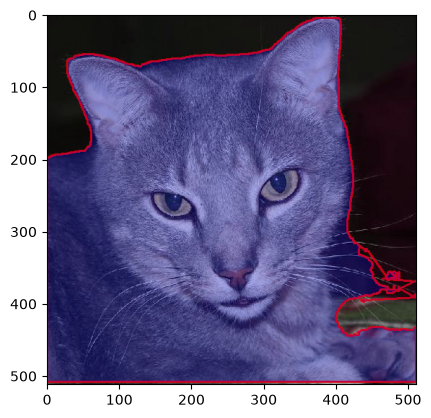

In [8]:
# print(result[0])
# print(len(result[0].boxes))
myimage = cv2.imread(img)
overlay = myimage.copy()
myimage = cv2.cvtColor(myimage, cv2.COLOR_BGR2RGB)
# plt.imshow(myimage)

# for box in result[0].boxes:
#     print(box)
#     class_id = result[0].names[box.cls[0].item()]
#     print(class_id)
#     coor = box.xyxy[0].tolist()
#     coors = [round(x) for x in coor]
#     print(coors)
#     cf = round(box.conf[0].item(), 2)
#     print(cf)
#     myimage = cv2.rectangle(myimage, (coors[0], coors[1]), (coors[2], coors[3]), (255,0,0))

print("mask = ", len(result[0].masks))
for idx in range(len(result[0].masks)):
    # print(mask)
    x = result[0].masks.xy[idx].astype(int)
    pts = x.reshape((-1, 1, 2))
    myimage = cv2.polylines(myimage, [pts], isClosed=True, color=(255, 0, 0), thickness=2)
    overlay = cv2.fillPoly(overlay, pts=[pts], color=(0, 0, 255))
    print("x = ", x)
    break
alpha = 0.25
myimage = cv2.addWeighted(overlay, alpha, myimage, 1 - alpha, 0)

plt.imshow(myimage)